# Dog Breed Image Classification

This notebook lists all the steps that you need to complete the complete this project. You will need to complete all the TODOs in this notebook as well as in the README and the two python scripts included with the starter code.


This project consists of creating a full machine learning workflow to fine-tune and deploy a dog breed image classification model based on the ResNet50 model

**Note:** This notebook has a bunch of code and markdown cells with TODOs that you have to complete. These are meant to be helpful guidelines for you to finish your project while meeting the requirements in the project rubrics. Feel free to change the order of these the TODO's and use more than one TODO code cell to do all your tasks.

In [ ]:
# TODO: Install any packages that you might need
# For instance, you will need the smdebug package
# !pip install -U smdebug  <- deprecated. An alternative is proposed below

In [1]:
# TODO: Import any packages that you might need
# For instance you will need Boto3 and Sagemaker
import os
import sagemaker
import boto3
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.train.tuner import HyperparameterTuner
from sagemaker.core.parameter import (
    IntegerParameter,
    CategoricalParameter,
    ContinuousParameter,
)
import boto3

sagemaker_session = Session()

bucket = sagemaker_session.default_bucket()

role = get_execution_role()

region = boto3.session.Session().region_name

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


## Dataset
The dataset being used is the dog breed classification dataset. It consists thousands of dog images classified by the different breed types

In [ ]:
#TODO: Fetch data
# Command to download and unzip data
# !wget https://s3-us-west-1.amazonaws.com/udacity-aind/dog-project/dogImages.zip
# !unzip data/dogImages.zip


In [ ]:
# Added this code block to find and delete the corrupted image in the dataset that was causing the training job to fail
from pathlib import Path
from PIL import Image

data_dir = Path("data/dogImages")
checked = 0
corrupted = []

for path in data_dir.rglob("*"):
    if path.is_file():
        checked += 1
        try:
            with Image.open(path) as image:
                image.load()  # Fully decodes the image
        except Exception as error:
            corrupted.append(path)
            print(f"Corrupted image: {path} -> {error}")

print(f"Checked files: {checked}")
print(f"Corrupted files: {len(corrupted)}")

In [ ]:
# The corrupted image found above was removed before uploading
!aws s3 sync ./data/dogImages/ s3://sagemaker-us-east-1-950885994135/project/data/

In [ ]:
!aws s3 ls s3://sagemaker-us-east-1-950885994135/project/data/

In [ ]:
!aws s3 ls s3://sagemaker-us-east-1-950885994135/project/data/ --recursive --summarize | tail -2

In [ ]:
# If this prints nothing, your the local files and S3 match and the upload is complete
!aws s3 sync data/dogImages s3://sagemaker-us-east-1-950885994135/project/data/ --dryrun

In [2]:
# Number of breeds (this is required so that we can properly define the number of neurons the output layer has
num_classes = len([d for d in os.listdir("data/dogImages/train") if os.path.isdir(os.path.join("data/dogImages/train", d))])
print(num_classes)

133


In [ ]:
# # Debugging code block used to test the train.py script
# from argparse import Namespace

# args = Namespace(
#     train_dir="data/dogImages/train",
#     valid_dir="data/dogImages/valid",
#     test_dir="data/dogImages/test",
#     batch_size=256,
#     num_classes=num_classes,
#     model_dir = "model/",
#     epochs=2,
#     lr=0.01
# )


# from train import main
# # train_loader, valid_loader, test_loader = create_data_loaders(args)
# main(args)

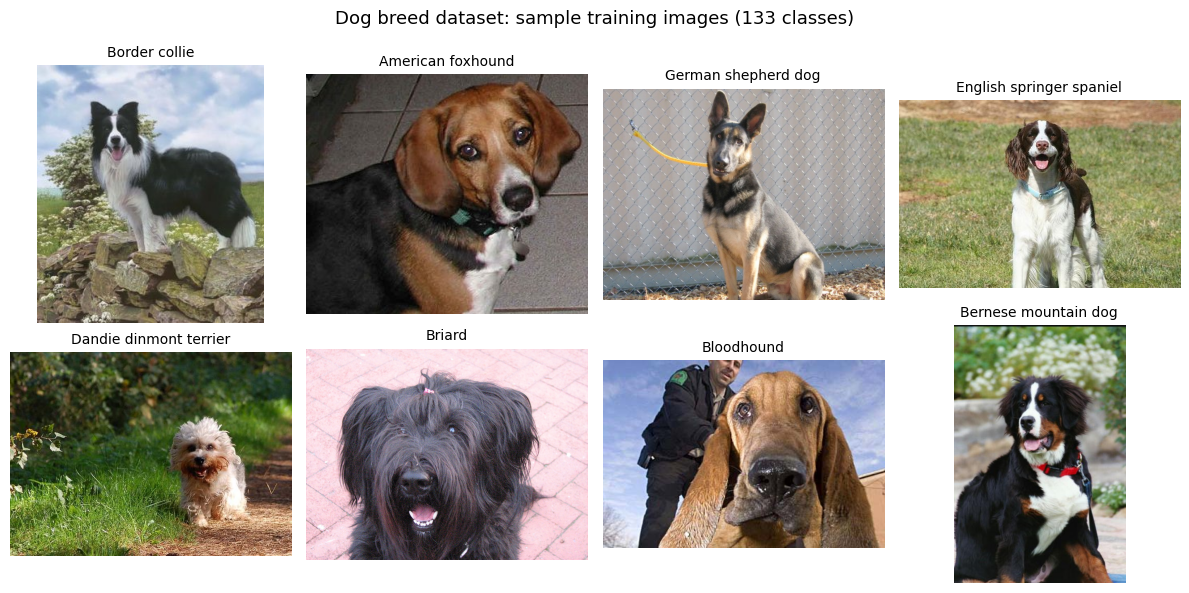

In [54]:
# Dataset sample
import os, random
import matplotlib.pyplot as plt
from PIL import Image

train_dir = "data/dogImages/train"
os.makedirs("images", exist_ok=True)

random.seed(42)                                  # same images every run
breeds = random.sample(sorted(os.listdir(train_dir)), 8)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, breed in zip(axes.flat, breeds):
    folder = os.path.join(train_dir, breed)
    img = Image.open(os.path.join(folder, random.choice(os.listdir(folder)))).convert("RGB")
    ax.imshow(img)
    ax.set_title(breed.split(".", 1)[1].replace("_", " "), fontsize=10)   # "006.American_eskimo_dog" -> "American eskimo dog"
    ax.axis("off")

fig.suptitle("Dog breed dataset: sample training images (133 classes)", fontsize=13)
plt.tight_layout()
plt.savefig("images/dataset_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## Hyperparameter Tuning
**TODO:** This is the part where you will finetune a pretrained model with hyperparameter tuning. Remember that you have to tune a minimum of two hyperparameters. However you are encouraged to tune more. You are also encouraged to explain why you chose to tune those particular hyperparameters and the ranges.

**Note:** You will need to use the `hpo.py` script to perform hyperparameter tuning.

In [3]:
#TODO: Declare your HP ranges, metrics etc.
hyperparameter_ranges = {
    # Learning rate for Adam. Range sampled with "Auto" scaling, so most trials land in 0.01–0.1 (high for Adam).
    # Better: ContinuousParameter(1e-4, 1e-2, scaling_type="Logarithmic") to explore each order of magnitude evenly.
    "lr": ContinuousParameter(0.001, 0.1, scaling_type="Logarithmic"),
    "batch-size": CategoricalParameter([32, 64, 128]),
    # "epochs": IntegerParameter(2, 4)
}

objective_metric_name = "average validation loss"
objective_type = "Minimize"
metric_definitions = [{"Name": "average validation loss", "Regex": "Validation Loss: ([0-9\\.]+)"}]

In [4]:
#TODO: Create estimators for your HPs
from sagemaker.train import ModelTrainer
from sagemaker.train.configs import Compute, SourceCode, StoppingCondition, OutputDataConfig, InputData
from sagemaker.core import image_uris

image_uri = image_uris.retrieve(
    framework="pytorch",
    region=sagemaker_session.boto_region_name,
    version="2.6",
    py_version="py312",
    image_scope="training",
    instance_type="ml.g4dn.xlarge"
)

trainer = ModelTrainer(
    training_image=image_uri,
    role=role,
    compute=Compute(instance_type="ml.g4dn.xlarge", instance_count=1),
    source_code=SourceCode(source_dir=".", entry_script="hpo.py"),
    sagemaker_session=sagemaker_session,
    base_job_name="hyperparameter-tuning",
    stopping_condition=StoppingCondition(
        max_runtime_in_seconds=3600
    ),
    output_data_config=OutputDataConfig(s3_output_path=f"s3://{bucket}/project/hpo")
)  # TODO: Your estimator here

print(image_uri)
print(trainer)

[10/21/26 06:40:06] INFO     OutputDataConfig compression type not provided. Using default:         ]8;id=11730932;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=11730933;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#165\165]8;;\
                             GZIP                                                                                  

                    INFO     Training image URI:                                               ]8;id=11730940;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py\model_trainer.py]8;;\:]8;id=11730941;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py#558\558]8;;\
                             763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:2.6                     
                             -gpu-py312                                                                            

763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:2.6-gpu-py312
training_mode=<Mode.SAGEMAKER_TRAINING_JOB: 'SAGEMAKER_TRAINING_JOB'> sagemaker_session=<sagemaker.core.helper.session_helper.Session object at 0x7f65e03d9bb0> role='arn:aws:iam::950885994135:role/service-role/AmazonSageMaker-ExecutionRole-20261013T173018' base_job_name='hyperparameter-tuning' source_code=SourceCode(source_dir='.', requirements=None, entry_script='hpo.py', command=None, ignore_patterns=['.env', '.git', '__pycache__', '.DS_Store', '.cache', '.ipynb_checkpoints']) distributed=None compute=Compute(instance_type='ml.g4dn.xlarge', instance_count=1, volume_size_in_gb=30, volume_kms_key_id=None, keep_alive_period_in_seconds=None, instance_groups=None, training_plan_arn=None, instance_placement_config=None, enable_managed_spot_training=None) networking=None stopping_condition=StoppingCondition(max_runtime_in_seconds=3600, max_wait_time_in_seconds=Unassigned(), max_pending_time_in_seconds=Unassigned()) 

In [5]:
tuner = HyperparameterTuner(
    model_trainer=trainer,
    objective_metric_name=objective_metric_name,
    hyperparameter_ranges=hyperparameter_ranges,
    metric_definitions=metric_definitions,
    objective_type=objective_type,
    max_jobs=4,
    max_parallel_jobs=2,
    base_tuning_job_name="dog-breed-hpo"
)  # TODO: Your tuner here

In [6]:
# TODO: Fit your HP Tuner

train_input = f"s3://{bucket}/project/data/train/"
valid_input = f"s3://{bucket}/project/data/valid/"
test_input = f"s3://{bucket}/project/data/test/"

print(train_input)
print(valid_input)
print(test_input)

s3://sagemaker-us-east-1-950885994135/project/data/train/
s3://sagemaker-us-east-1-950885994135/project/data/valid/
s3://sagemaker-us-east-1-950885994135/project/data/test/


In [ ]:
# Train tunes the model; validation compares HPO trials. Channel names must match SM_CHANNEL_TRAIN and SM_CHANNEL_VALID.
# So the channel names should be "train" and "valid", we cannot use "training" and "validation"
tuner.tune(
    inputs=[
        InputData(channel_name="train", data_source=train_input),
        InputData(channel_name="valid", data_source=valid_input),
    ],
    wait=True
) # TODO: Remember to include your data channels

In [ ]:
# TODO: Get the best estimators and the best HPs
best_job_name = tuner.best_training_job()
print(f"Best training job: {best_job_name}")

# best_estimator = #TODO

#Get the hyperparameters of the best trained model
# best_estimator.hyperparameters()

In [7]:
# # In case the kernel died, we can find the best hyperparameters after the tuning job is done
import boto3

sm = boto3.client("sagemaker")

# ── 1. Find the most recent completed tuning job ───────────────────────────────
tuning_jobs = sm.list_hyper_parameter_tuning_jobs(
    SortBy="CreationTime",
    SortOrder="Descending",
    MaxResults=5,
)["HyperParameterTuningJobSummaries"]

print("Recent tuning jobs:")
for j in tuning_jobs:
    print(f"  {j['HyperParameterTuningJobName']}  |  {j['HyperParameterTuningJobStatus']}")

# Pick the most recent completed one
tuning_job = next(
    j for j in tuning_jobs if j["HyperParameterTuningJobStatus"] == "Completed"
)
tuning_job_name = tuning_job["HyperParameterTuningJobName"]
print(f"\nUsing tuning job: {tuning_job_name}")

# ── 2. Get the best training job and its hyperparameters ───────────────────────
tuning_info = sm.describe_hyper_parameter_tuning_job(
    HyperParameterTuningJobName=tuning_job_name
)
best = tuning_info["BestTrainingJob"]
best_job_name = best["TrainingJobName"]
best_hps      = best["TunedHyperParameters"]
best_metric   = best["FinalHyperParameterTuningJobObjectiveMetric"]

print(f"\nBest training job : {best_job_name}")
print(f"Best hyperparameters:")
for k, v in best_hps.items():
    print(f"  {k}: {v}")
    print(f"  {k} type: {type(v)}")
print(f"Best metric — {best_metric['MetricName']}: {best_metric['Value']:.4f}")


Recent tuning jobs:
  dog-breed-hpo-261020-1604  |  Completed
  dog-breed-hpo-261020-0722  |  Completed
  dog-breed-hpo-261019-1557  |  Completed
  pytorch-training-261019-1531  |  Completed
  pytorch-training-261019-1508  |  Failed

Using tuning job: dog-breed-hpo-261020-1604

Best training job : dog-breed-hpo-261020-1604-003-59525e4c
Best hyperparameters:
  batch-size: 32
  batch-size type: <class 'str'>
  lr: 0.0014467593879787363
  lr type: <class 'str'>
Best metric — average validation loss: 0.5652


In [55]:
# Debugging code block to see the results of the different runs of the tuning job
# View all results and top hyperparameters in a pandas DataFrame

import json
import pandas as pd

def clean(v):
    try:
        return json.loads(v)          # '"64"' -> 64, '0.0032' -> 0.0032
    except (ValueError, TypeError):
        return v

jobs = sm.list_training_jobs_for_hyper_parameter_tuning_job(
    HyperParameterTuningJobName=tuning_job_name,
    MaxResults=100,
)["TrainingJobSummaries"]

rows = []
for j in jobs:
    row = {k: clean(v) for k, v in j["TunedHyperParameters"].items()}
    row["TrainingJobName"] = j["TrainingJobName"]
    row["Status"] = j["TrainingJobStatus"]
    row["FinalObjectiveValue"] = j.get("FinalHyperParameterTuningJobObjectiveMetric", {}).get("Value")
    rows.append(row)

df = pd.DataFrame(rows).sort_values("FinalObjectiveValue", ascending=True)   # Minimize -> lowest first
print(df)

best_hps = {k: clean(v) for k, v in best_hps.items()}
print("\nBest hyperparameters to reuse:", best_hps)

   batch-size        lr                         TrainingJobName     Status  \
1          32  0.001447  dog-breed-hpo-261020-1604-003-59525e4c  Completed   
2          64  0.007484  dog-breed-hpo-261020-1604-002-3d323d32  Completed   
3          32  0.005815  dog-breed-hpo-261020-1604-001-1948f5cf  Completed   
0         128  0.015511  dog-breed-hpo-261020-1604-004-21759fde  Completed   

   FinalObjectiveValue  
1               0.5652  
2               0.6627  
3               0.7176  
0               0.8384  

Best hyperparameters to reuse: {'batch-size': 32, 'lr': 0.0014467593879787363}


## Model Profiling and Debugging
TODO: Using the best hyperparameters, create and finetune a new model

**Note:** You will need to use the `train.py` script to perform model profiling and debugging.

SageMaker Debugger/Profiler (`DebuggerHookConfig`, `ProfilerConfig`, rules) can't be attached to a v3 `ModelTrainer`, so `train.py` now does the equivalent itself:
- **TensorBoard** + `metrics.csv` (step losses, mean |gradient|, weight/gradient histograms of the trainable head, torch.profiler trace)
- an in-script **system monitor** (CPU/GPU/memory every 500 ms) -> `system_metrics.csv`
- in-script **rules** (LossNotDecreasing, VanishingGradient, Overfit, Overtraining, + profiler checks) -> `rules.json`

All results come back in `output.tar.gz`.

In [8]:
# TODO: Set up debugging and profiling rules and hooks
# The hooks and rules now live inside train.py; this cell prepares the job
import os
import shutil
import boto3
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.core import image_uris



data_s3 = f"s3://{bucket}/project/data"
output_s3 = f"s3://{bucket}/project/profiling-debugging"
tensorboard_s3 = f"{output_s3}/tensorboard"

# Dedicated source dir: using "." would upload data/dogImages (~1.1 GB) along with the code.
# train.py stays at the project root (used by the local debugging block) and is copied here.
source_dir = "scripts"
os.makedirs(source_dir, exist_ok=True)
shutil.copy("train.py", f"{source_dir}/train.py")

# smdebug is no longer needed; tensorboard + psutil are
with open(f"{source_dir}/requirements.txt", "w") as f:
    f.write("tensorboard\npsutil\n")

# training_image = f"763104351884.dkr.ecr.{region}.amazonaws.com/pytorch-training:1.13.1-gpu-py39"
training_image = image_uris.retrieve(
    framework="pytorch",
    region=region,
    version="2.6",
    py_version="py312",
    image_scope="training",
    instance_type="ml.g4dn.xlarge"
)


# TODO: replace with the best hyperparameters from the HPO section
hyperparameters = {
    "lr": best_hps["lr"],
    "batch-size": best_hps["batch-size"],
    "epochs": 5,
    "num-classes": num_classes,
}

print(role)
print(data_s3)
print(output_s3)
print(training_image)

arn:aws:iam::950885994135:role/service-role/AmazonSageMaker-ExecutionRole-20261013T173018
s3://sagemaker-us-east-1-950885994135/project/data
s3://sagemaker-us-east-1-950885994135/project/profiling-debugging
763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:2.6-gpu-py312


In [9]:
!python -m py_compile scripts/train.py && echo "OK"

OK


In [10]:
# TODO: Create and fit an estimator
from sagemaker.train import ModelTrainer
from sagemaker.core.training.configs import (
    Compute,
    InputData,
    OutputDataConfig,
    SourceCode,
    StoppingCondition,
)

trainer = ModelTrainer(
    training_image=training_image,
    role=role,
    sagemaker_session=sagemaker_session,
    base_job_name="dog-breed-profiling-sagemaker-v3",
    source_code=SourceCode(
        source_dir=source_dir,
        requirements="requirements.txt",
        entry_script="train.py",
    ),
    region=region,
    compute=Compute(instance_type="ml.g4dn.xlarge", instance_count=1),
    output_data_config=OutputDataConfig(s3_output_path=output_s3),
    hyperparameters=hyperparameters,
    stopping_condition=StoppingCondition(max_runtime_in_seconds=3600),
)

# Optional: live upload of TensorBoard logs to S3 (needed for the SageMaker TensorBoard app).
# Not required: the logs are also inside output.tar.gz.
try:
    from sagemaker.core.shapes import TensorBoardOutputConfig
    trainer = trainer.with_tensorboard_output_config(
        TensorBoardOutputConfig(s3_output_path=tensorboard_s3, local_path="/opt/ml/output/tensorboard")
    )
    print("TensorBoardOutputConfig attached ->", tensorboard_s3)
except Exception as e:
    print("TensorBoardOutputConfig not attached (fine, logs are in output.tar.gz):", e)

[10/21/26 06:48:52] INFO     OutputDataConfig compression type not provided. Using default:         ]8;id=11730946;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=11730947;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#165\165]8;;\
                             GZIP                                                                                  

                    INFO     Training image URI:                                               ]8;id=11730952;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py\model_trainer.py]8;;\:]8;id=11730953;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py#558\558]8;;\
                             763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:2.6                     
                             -gpu-py312                                                                            

TensorBoardOutputConfig attached -> s3://sagemaker-us-east-1-950885994135/project/profiling-debugging/tensorboard


In [11]:
# Channel names must match SM_CHANNEL_TRAIN / SM_CHANNEL_VALID / SM_CHANNEL_TEST in train.py
trainer.train(
    input_data_config=[
        InputData(channel_name="train", data_source=f"{data_s3}/train/"),
        InputData(channel_name="valid", data_source=f"{data_s3}/valid/"),
        InputData(channel_name="test",  data_source=f"{data_s3}/test/"),
    ],
    wait=True,
)

[10/21/26 06:49:43] INFO     SageMaker Python SDK will collect telemetry to help us better ]8;id=11730960;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/telemetry/telemetry_logging.py\telemetry_logging.py]8;;\:]8;id=11730961;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/telemetry/telemetry_logging.py#322\322]8;;\
                             understand our user's needs, diagnose issues, and deliver                             
                             additional features.                                                                  
                             To opt out of telemetry, please disable via TelemetryOptOut                           
                             parameter in SDK defaults config. For more information, refer                         
                             to                                                                                    
                             https://sagemaker.readthedocs.io/en/stable/overview.html#conf                         
                             iguring-and-using-defaults-with-the-sagemaker-python-sdk.                             

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


[10/21/26 06:49:44] INFO     Creating training_job resource.                                     ]8;id=11730968;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=11730969;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31238\31238]8;;\

                    WARNING  No region provided. Using default region.                                 ]8;id=11730976;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/utils/utils.py\utils.py]8;;\:]8;id=11730977;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/utils/utils.py#361\361]8;;\

Output()

...

                    INFO     dog-breed-profiling-sagemaker-v3-20261021064943/algo-1-1792565539:  ]8;id=11731937;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=11731938;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31584\31584]8;;\
                             [RULE] DataLoaderBottleneck: ok (10% of step time spent waiting for                   
                             data)                                                                                 

                    INFO     dog-breed-profiling-sagemaker-v3-20261021064943/algo-1-1792565539:  ]8;id=11731943;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=11731944;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31584\31584]8;;\
                             [RULE] LowGPUUtilization: ok (median GPU utilisation=83%)                             

                    INFO     dog-breed-profiling-sagemaker-v3-20261021064943/algo-1-1792565539:  ]8;id=11731949;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=11731950;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31584\31584]8;;\
                             Training Container Execution Completed                                                

                    INFO     dog-breed-profiling-sagemaker-v3-20261021064943/algo-1-1792565539:  ]8;id=11731955;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=11731956;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31584\31584]8;;\
                             ++ echo 'Training Container Execution Completed'                                      

[10/21/26 07:04:36] INFO     Final Resource Status: Completed                                    ]8;id=11731962;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=11731963;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31590\31590]8;;\

In [12]:
training_job_name = trainer._latest_training_job.training_job_name
print(f"Training job name: {training_job_name}")

sm_client = boto3.client("sagemaker", region_name=region)
job_description = sm_client.describe_training_job(TrainingJobName=training_job_name)

# output.tar.gz sits next to model.tar.gz
model_artifacts = job_description["ModelArtifacts"]["S3ModelArtifacts"]
output_tar = model_artifacts.replace("model.tar.gz", "output.tar.gz")
print(model_artifacts)
print(output_tar)

Training job name: dog-breed-profiling-sagemaker-v3-20261021064943
s3://sagemaker-us-east-1-950885994135/project/profiling-debugging/dog-breed-profiling-sagemaker-v3-20261021064943/output/model.tar.gz
s3://sagemaker-us-east-1-950885994135/project/profiling-debugging/dog-breed-profiling-sagemaker-v3-20261021064943/output/output.tar.gz


In [13]:
# Replaces create_trial(...): download and extract everything the script produced
local_dir = f"./job_output/{training_job_name}"
os.makedirs(local_dir, exist_ok=True)
!aws s3 cp {output_tar} {local_dir}/output.tar.gz
!tar -xzf {local_dir}/output.tar.gz -C {local_dir}
!ls -R {local_dir} | head -40

download: s3://sagemaker-us-east-1-950885994135/project/profiling-debugging/dog-breed-profiling-sagemaker-v3-20261021064943/output/output.tar.gz to job_output/dog-breed-profiling-sagemaker-v3-20261021064943/output.tar.gz
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.creationtime'
./job_output/dog-breed-profiling-sagemaker-v3-2026102106494

### Debugger equivalent: tracked losses and gradients

datapoints in TRAIN mode: 1045
datapoints in EVAL mode : 135


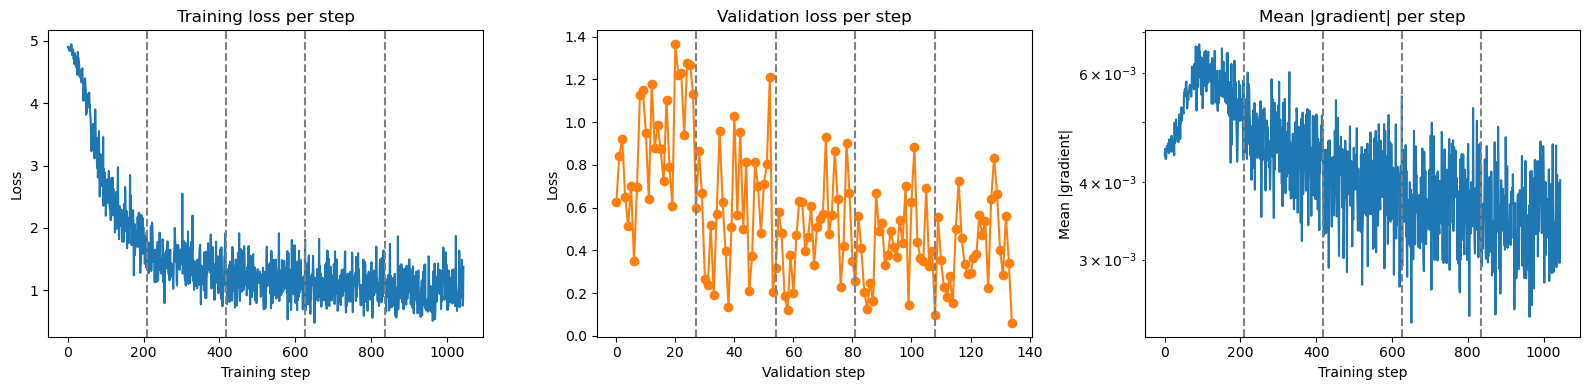

In [63]:
# Plot debugging outputs
import pandas as pd
import matplotlib.pyplot as plt

metrics = pd.read_csv(f"{local_dir}/metrics.csv")
metrics["mean_abs_grad"] = pd.to_numeric(
    metrics["mean_abs_grad"], errors="coerce"
)

tr = metrics[metrics["mode"] == "TRAIN"]
ev = metrics[metrics["mode"] == "EVAL"]

print("datapoints in TRAIN mode:", len(tr))
print("datapoints in EVAL mode :", len(ev))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# 1. Training loss
ax[0].plot(tr["step"], tr["loss"])
ax[0].set_title("Training loss per step")
ax[0].set_xlabel("Training step")
ax[0].set_ylabel("Loss")

# 2. Validation loss
ax[1].plot(ev["step"], ev["loss"], marker="o", color="tab:orange")
ax[1].set_title("Validation loss per step")
ax[1].set_xlabel("Validation step")
ax[1].set_ylabel("Loss")

# 3. Gradients
ax[2].plot(tr["step"], tr["mean_abs_grad"])
ax[2].set_yscale("log")
ax[2].set_title("Mean |gradient| per step")
ax[2].set_xlabel("Training step")
ax[2].set_ylabel("Mean |gradient|")

# Epoch boundaries
for e in sorted(metrics["epoch"].unique())[1:]:
    ax[0].axvline(tr[tr["epoch"] == e]["step"].min(), ls="--", c="grey")
    ax[1].axvline(ev[ev["epoch"] == e]["step"].min(), ls="--", c="grey")
    ax[2].axvline(tr[tr["epoch"] == e]["step"].min(), ls="--", c="grey")

fig.tight_layout()
fig.savefig(
    "images/debugging_metrics.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

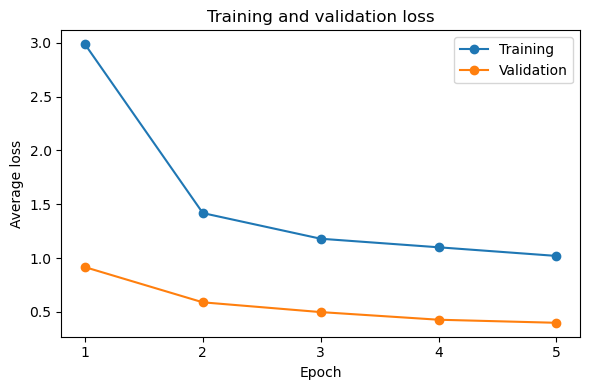

mode,EVAL,TRAIN
epoch,,
1,0.916422,2.984998
2,0.589729,1.418151
3,0.499113,1.179949
4,0.428261,1.100594
5,0.399773,1.020453


In [64]:
# Plot epoch-level training and validation loss
epoch_loss = (
    metrics.groupby(["epoch", "mode"])["loss"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(
    epoch_loss.index,
    epoch_loss["TRAIN"],
    marker="o",
    label="Training"
)

ax.plot(
    epoch_loss.index,
    epoch_loss["EVAL"],
    marker="o",
    label="Validation"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Average loss")
ax.set_title("Training and validation loss")
ax.set_xticks(epoch_loss.index)
ax.legend()

fig.tight_layout()
fig.savefig(
    "images/training_validation_loss.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

display(epoch_loss)

### Rules (replaces rule-output)

In [15]:
import json
from IPython.display import HTML, display

report = json.load(open(f"{local_dir}/rules.json"))
rules_df = pd.DataFrame([
    {"rule": k, "status": "TRIGGERED" if v["triggered"] else "ok", "detail": v["detail"]}
    for k, v in report["rules"].items()
])
display(HTML("<h3>Rules</h3>" + rules_df.to_html(index=False)))
display(HTML("<h3>Epochs</h3>" + pd.DataFrame(report["epochs"]).round(3).to_html(index=False)))
print(f"Test loss: {report['test']['test_loss']:.4f} | Test accuracy: {100 * report['test']['test_acc']:.2f}%")
t = report["timing"]
print(f"Data loading: {t['data_loading_s']:.1f}s | Compute: {t['compute_s']:.1f}s")

rule,status,detail
LossNotDecreasing,ok,"first 5 steps=4.883, last 5 steps=1.079"
VanishingGradient,ok,min mean|grad|=2.37e-03
Overfit,ok,val/train loss ratio=0.40
Overtraining,ok,"val losses per epoch=[0.909, 0.603, 0.504, 0.429, 0.412]"
DataLoaderBottleneck,ok,10% of step time spent waiting for data
LowGPUUtilization,ok,median GPU utilisation=83%


epoch,train_loss,val_loss,val_acc,time_s
1,2.986,0.909,0.760,28.760
2,1.418,0.603,0.813,26.862
3,1.179,0.504,0.831,27.033
4,1.101,0.429,0.863,26.829
5,1.020,0.412,0.872,26.963


Test loss: 0.4530 | Test accuracy: 86.36%
Data loading: 11.8s | Compute: 106.0s


**TODO**: Is there some anomalous behaviour in your debugging output? If so, what is the error and how will you fix it?  
**TODO**: If not, suppose there was an error. What would that error look like and how would you have fixed it?

No rules were triggered, but suppose the learning rate was too high, for example lr=1.0 instead of the tuned lr≈0.00144, the output would show:
    - LossNotDecreasing triggered: the training loss would stay flat or jump around instead of steadily decreasing
    - Unstable gradient: mean|grad| will increase significantly, a,d the loss would become NaN
    - Validation accuracy would not improve after each epoch

In this case, the fix would be to lower the learning rate to the range found in the hyperparameter tuning section (around lr≈0.001)

### Profiler equivalent: system timeline (replaces TimelineCharts)

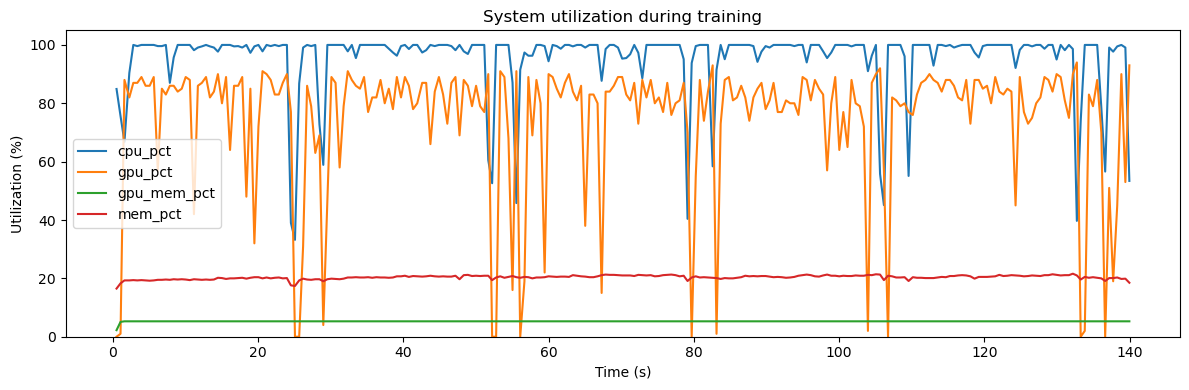

,time_s,cpu_pct,mem_pct,gpu_pct,gpu_mem_pct
mean,70.184418,95.468675,20.370281,74.943775,5.266979
50%,70.130000,100.000000,20.400000,83.000000,5.279948
max,139.970000,100.000000,21.600000,94.000000,5.279948


In [65]:
# Display the profiler output
sysm = pd.read_csv(f"{local_dir}/system_metrics.csv")

fig, ax = plt.subplots(figsize=(12, 4))

for col in ["cpu_pct", "gpu_pct", "gpu_mem_pct", "mem_pct"]:
    if sysm[col].notna().any():
        ax.plot(sysm["time_s"], sysm[col], label=col)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Utilization (%)")
ax.set_ylim(0, 105)
ax.set_title("System utilization during training")
ax.legend()

fig.tight_layout()
fig.savefig(
    "images/system_profiling.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

display(
    sysm.describe().loc[["mean", "50%", "max"]]
)

In [17]:
# Framework profiling: top operators (from torch.profiler, first epoch)
print(open(f"{local_dir}/torch_profiler_summary.txt").read())

-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                          ProfilerStep*         0.00%       0.000us         0.00%       0.000us       0.000us     287.111ms       106.90%     287.111ms      95.704ms           0 b           0 b           0 b           0 

### Generating html profiler report (replaces profiler-report.html)


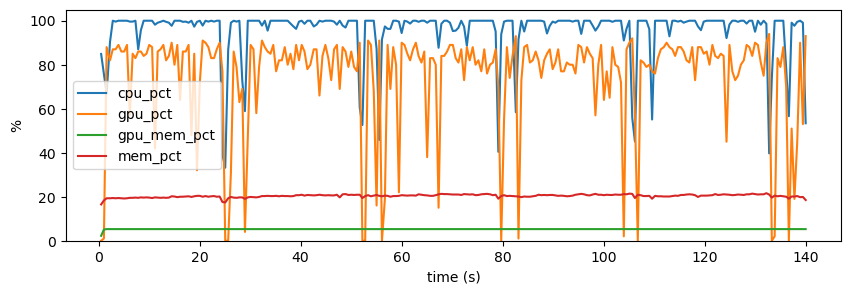

In [18]:
import base64, io, html

report = json.load(open(f"{local_dir}/rules.json"))
sysm = pd.read_csv(f"{local_dir}/system_metrics.csv")
torch_table = open(f"{local_dir}/torch_profiler_summary.txt").read()

def fig_to_img(fig):
    buf = io.BytesIO(); fig.savefig(buf, format="png", bbox_inches="tight"); plt.close(fig)
    return f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}"/>'

# System utilisation chart
fig, ax = plt.subplots(figsize=(10, 3))
for col in ["cpu_pct", "gpu_pct", "gpu_mem_pct", "mem_pct"]:
    if sysm[col].notna().any():
        ax.plot(sysm["time_s"], sysm[col], label=col)
ax.set_ylim(0, 105); ax.set_xlabel("time (s)"); ax.set_ylabel("%"); ax.legend()
sys_img = fig_to_img(fig)

# Recommendations for each triggered rule
advice = {
    "DataLoaderBottleneck": "JPEG decoding + RandomResizedCrop is CPU-bound: raise num_workers up to the vCPU count, set pin_memory=True, or pre-resize the images.",
    "LowGPUUtilization": "GPU is often idle (frozen backbone + data loading): speed up data loading, or use a smaller/cheaper instance.",
    "LossNotDecreasing": "Lower the learning rate, or check that the fc head parameters are the ones passed to the optimizer.",
    "Overfit": "Validation loss >> training loss: add regularization (dropout, weight decay) or more augmentation.",
    "Overtraining": "Validation loss stopped improving: use early stopping / fewer epochs.",
    "VanishingGradient": "Check initialization, activation functions, learning rate.",
}
rows = "".join(
    f"<tr><td>{k}</td><td style='color:{'red' if v['triggered'] else 'green'}'>"
    f"{'TRIGGERED' if v['triggered'] else 'ok'}</td><td>{html.escape(v['detail'])}</td>"
    f"<td>{advice.get(k, '') if v['triggered'] else ''}</td></tr>"
    for k, v in report["rules"].items()
)
t = report["timing"]
stats = sysm.describe().loc[["mean", "50%", "max"]].round(1).to_html()

page = f"""<html><body style="font-family:sans-serif">
<h1>Profiler report - {training_job_name}</h1>
<h2>Rules summary</h2>
<table border=1 cellpadding=4><tr><th>Rule</th><th>Status</th><th>Detail</th><th>Recommendation</th></tr>{rows}</table>
<h2>Step time breakdown</h2>
<p>Data loading: {t['data_loading_s']:.1f}s | Compute: {t['compute_s']:.1f}s</p>
<h2>System utilisation</h2>{sys_img}{stats}
<h2>Top operators (torch.profiler)</h2><pre>{html.escape(torch_table)}</pre>
</body></html>"""

with open("profiler-report.html", "w") as f:
    f.write(page)
display(HTML(page))

### Optional: open TensorBoard (histograms, profiler trace)

Either use the **SageMaker TensorBoard** app (if `TensorBoardOutputConfig` was attached), or run it locally from the notebook. The profiler trace tab needs the `torch-tb-profiler` plugin. The command blocks the cell, so interrupt the kernel to stop it.

In [59]:
# # Local TensorBoard from the extracted logs (in Studio JupyterLab, open via the proxy URL:
# # https://<your-studio-url>/jupyterlab/default/proxy/6006/)
!pip install -q torch-tb-profiler
!pip install -q "setuptools<81"
!tensorboard --logdir {local_dir}/tensorboard --port 6006 --bind_all

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dash 2.18.1 requires dash-core-components==2.0.0, which is not installed.
dash 2.18.1 requires dash-html-components==2.0.0, which is not installed.
dash 2.18.1 requires dash-table==5.0.0, which is not installed.
sagemaker-studio 1.1.32 requires pymongo-auth-aws>=1.3.0, which is not installed.
sagemaker-studio 1.1.32 requires pymongosql>=0.7.2, which is not installed.
dash 2.18.1 requires Flask<3.1,>=1.0.4, but you have flask 3.1.3 which is incompatible.
dash 2.18.1 requires Werkzeug<3.1, but you have werkzeug 3.1.8 which is incompatible.
/opt/conda/lib/python3.12/site-packages/tensorboard/default.py:30: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this packa

## Model Deploying

In [24]:
# Retrieve inference image
inference_image_uri = image_uris.retrieve(
    framework="pytorch",
    region=region,
    version="2.6",
    py_version="py312",
    image_scope="inference",
    instance_type="ml.m5.large"
)

inference_image_uri

'763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-inference:2.6-cpu-py312'

In [25]:
# Repack model.tar.gz so inference.py lives in code/ inside the model archive.
# The PyTorch >=1.6 inference containers only load user code from model.tar.gz/code/.
# They do NOT download SAGEMAKER_SUBMIT_DIRECTORY, so without this step the container
# falls back to default_model_fn (torch.jit.load) and the worker crashes on load.
import os
import shutil
import tarfile

s3 = boto3.client("s3")
src_bucket, src_key = model_artifacts.replace("s3://", "").split("/", 1)
s3.download_file(src_bucket, src_key, "model.tar.gz")

shutil.rmtree("repack", ignore_errors=True)
os.makedirs("repack/code")
with tarfile.open("model.tar.gz") as t:
    t.extractall("repack", filter="data")                      # -> repack/model.pth
shutil.copy("inference.py", "repack/code/inference.py")  # -> repack/code/inference.py

with tarfile.open("model_with_code.tar.gz", "w:gz") as t:
    for name in os.listdir("repack"):
        t.add(os.path.join("repack", name), arcname=name)

# Sanity check: should list model.pth and code/inference.py
with tarfile.open("model_with_code.tar.gz") as t:
    print(t.getnames())

model_with_code_url = sagemaker_session.upload_data(
    path="model_with_code.tar.gz", bucket=bucket, key_prefix=f"project/model-with-code"
)
print(f"Repacked model artifact: {model_with_code_url}")

['code', 'code/inference.py', 'model.pth', 'classes.json']
Repacked model artifact: s3://sagemaker-us-east-1-950885994135/project/model-with-code/model_with_code.tar.gz


In [27]:
# TODO: Deploy your model to an endpoint

from sagemaker.serve import ModelBuilder

# predictor=trainer.deploy(initial_instance_count=1, instance_type="ml.m5.large")  # TODO: Add your deployment configuration like instance type and number of instances

builder = ModelBuilder(
    model_path=model_with_code_url,
    image_uri=inference_image_uri,
    role_arn=role,
    env_vars={"SAGEMAKER_PROGRAM": "inference.py"},
)
model = builder.build()
model
# predictor = builder.deploy(initial_instance_count=1, instance_type="ml.t3.medium")
# print(f"\nEndpoint is live: {predictor.endpoint_name}")

[10/21/26 07:32:44] DEBUG    Auto-detecting optimal instance type for model...           ]8;id=11731978;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=11731979;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#340\340]8;;\

                    DEBUG    Using default CPU instance type: ml.m5.large                ]8;id=11731985;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=11731986;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#374\374]8;;\

[10/21/26 07:32:45] DEBUG    No ModelMetadata provided. ModelBuilder is not handling    ]8;id=11731992;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=11731993;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#1335\1335]8;;\
                             MLflow model input                                                                    

                    INFO     Creating model with name: model-1ff268e3                        ]8;id=11732000;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=11732001;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1922\1922]8;;\

                    INFO     ✅ Model has been created: 'model-1ff268e3' using server None in ]8;id=11732008;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py\model_builder.py]8;;\:]8;id=11732009;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py#3357\3357]8;;\
                             SAGEMAKER_ENDPOINT mode (ARN:                                                         
                             arn:aws:sagemaker:us-east-1:950885994135:model/model-1ff268e3)                        

Model(model_name='model-1ff268e3', primary_container=ContainerDefinition(container_hostname=Unassigned(), image='763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-inference:2.6-cpu-py312', image_config=Unassigned(), mode='SingleModel', model_data_url='s3://sagemaker-us-east-1-950885994135/project/model-with-code/model_with_code.tar.gz', model_data_source=ModelDataSource(s3_data_source=S3ModelDataSource(s3_data_type='S3Object', compression_type='Gzip', s3_uri='s3://sagemaker-us-east-1-950885994135/project/model-with-code/model_with_code.tar.gz', model_access_config=Unassigned(), hub_access_config=Unassigned(), manifest_s3_uri=Unassigned(), e_tag=Unassigned(), manifest_etag=Unassigned())), additional_model_data_sources=Unassigned(), environment={'SAGEMAKER_CONTAINER_LOG_LEVEL': '20', 'SAGEMAKER_PROGRAM': 'inference.py', 'SAGEMAKER_REGION': 'us-east-1', 'SAGEMAKER_SUBMIT_DIRECTORY': ''}, model_package_name=Unassigned(), inference_specification_name=Unassigned(), multi_model_config=Unas

In [28]:
predictor = builder.deploy(initial_instance_count=1, instance_type="ml.m5.large")

[10/21/26 07:33:14] INFO     Creating endpoint-config with name endpoint-ec2127bd            ]8;id=11732015;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=11732016;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1093\1093]8;;\

                    INFO     Creating endpoint with name endpoint-ec2127bd                   ]8;id=11732022;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=11732023;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1125\1125]8;;\

[10/21/26 07:33:15] WARNING  Failed to enable live logging: An error occurred                ]8;id=11732029;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=11732030;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#2844\2844]8;;\
                             (AccessDeniedException) when calling the FilterLogEvents                              
                             operation: User:                                                                      
                             arn:aws:sts::950885994135:assumed-role/AmazonSageMaker-Executio                       
                             nRole-20261013T173018/SageMaker is not authorized to perform:                         
                             logs:FilterLogEvents on resource:                                                     
                             arn:aws:logs:us-east-1:950885994135:log-group:/aws/sagemaker/En                       
                             dpoints/endpoint-ec2127bd because no identity-based policy                            
                             allows the logs:FilterLogEvents action. Fallback to default                           
                             logging...                                                                            

Output()

[10/21/26 07:36:46] INFO     ✅ Deployment successful: Endpoint 'endpoint-ec2127bd' using     ]8;id=11732036;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py\model_builder.py]8;;\:]8;id=11732037;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py#2687\2687]8;;\
                             None in SAGEMAKER_ENDPOINT mode (ARN:                                                 
                             arn:aws:sagemaker:us-east-1:950885994135:endpoint/endpoint-ec212                      
                             7bd)                                                                                  

In [36]:
endpoint_name = predictor.endpoint_name
print(endpoint_name)

endpoint-ec2127bd


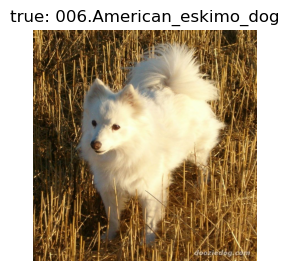

In [31]:
import os, random
import matplotlib.pyplot as plt
from PIL import Image

test_dir = "data/dogImages/test"
class_names = sorted(os.listdir(test_dir))   # same alphabetical order ImageFolder used in training

true_breed = random.choice(class_names)
img_path = os.path.join(test_dir, true_breed, random.choice(os.listdir(os.path.join(test_dir, true_breed))))

plt.figure(figsize=(3, 3))
plt.imshow(Image.open(img_path).convert("RGB"))
plt.title(f"true: {true_breed}")
plt.axis("off")
plt.show()

In [39]:
# TODO: Run an prediction on the endpoint

# image = # TODO: Your code to load and preprocess image to send to endpoint for prediction
# response = predictor.predict()

import json, boto3

with open(img_path, "rb") as f:
    payload = f.read()

runtime = boto3.client("sagemaker-runtime")
response = runtime.invoke_endpoint(
    EndpointName=endpoint_name,
    ContentType="image/jpeg",          # must be one of IMAGE_TYPES in inference.py
    Accept="application/json",
    Body=payload,
)

result = json.loads(response["Body"].read().decode("utf-8"))   # read the stream once

print(f"true: {true_breed}\n")
for p in result["predictions"]:
    breed = p["breed"] or class_names[p["index"]]   # fallback if classes.json wasn't saved
    print(f"{breed:<40} {p['probability']:.1%}")

true: 006.American_eskimo_dog

006.American_eskimo_dog                  95.6%
084.Icelandic_sheepdog                   2.5%
051.Chow_chow                            0.4%


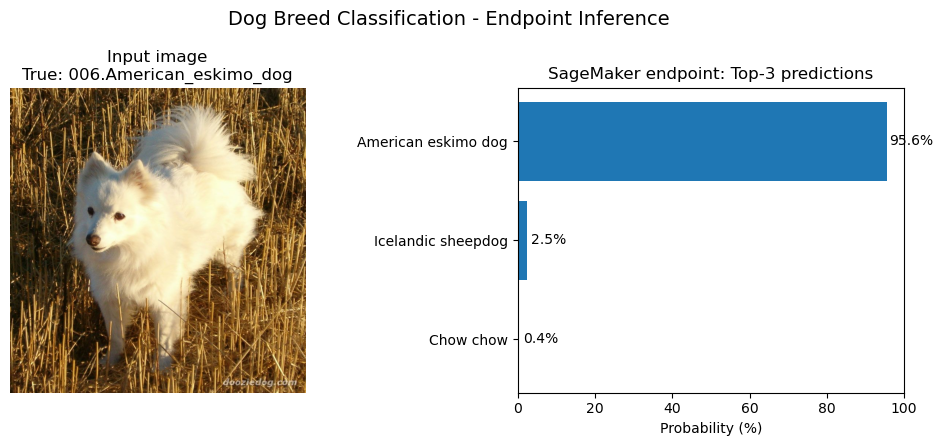

In [66]:
import matplotlib.pyplot as plt
from PIL import Image
import os

predictions = result["predictions"]

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))

# Input image
ax[0].imshow(Image.open(img_path).convert("RGB"))
ax[0].set_title(f"Input image\nTrue: {true_breed}")
ax[0].axis("off")

# Top-3 endpoint predictions
breeds = [
    p["breed"] if p["breed"] else class_names[p["index"]]
    for p in predictions
]
probs = [p["probability"] * 100 for p in predictions]

# Remove numeric prefix and replace underscores for display only
display_names = [
    breed.split(".", 1)[-1].replace("_", " ")
    for breed in breeds
]

bars = ax[1].barh(display_names[::-1], probs[::-1])

ax[1].set_xlabel("Probability (%)")
ax[1].set_title("SageMaker endpoint: Top-3 predictions")
ax[1].set_xlim(0, 100)

# Add probability labels
for bar, prob in zip(bars, probs[::-1]):
    ax[1].text(
        min(prob + 1, 96),
        bar.get_y() + bar.get_height() / 2,
        f"{prob:.1f}%",
        va="center"
    )

fig.suptitle("Dog Breed Classification - Endpoint Inference", fontsize=14)

plt.tight_layout()

os.makedirs("images", exist_ok=True)
fig.savefig(
    "images/inference_result.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [45]:
# # Debug code block to see what is actually stored in the model artifacts
# import tarfile, boto3
# s3 = boto3.client("s3")

# def list_tar(s3_url, local):
#     b, k = s3_url.replace("s3://", "").split("/", 1)
#     s3.download_file(b, k, local)
#     with tarfile.open(local) as t:
#         print(local, "->", t.getnames())

# list_tar(model_artifacts, "check_trained.tar.gz")         # output of the training job
# list_tar(model_with_code_url, "check_deployed.tar.gz")   # the archive you deployed, if you repacked

check_trained.tar.gz -> ['model.pth', 'classes.json']
check_deployed.tar.gz -> ['code', 'code/inference.py', 'model.pth', 'classes.json']


In [46]:
# TODO: Remember to shutdown/delete your endpoint once your work is done
# predictor.delete_endpoint()
predictor.delete()

╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:2                                                                                    │
│                                                                                                  │
│   1 # TODO: Remember to shutdown/delete your endpoint once your work is done                     │
│ ❱ 2 predictor.delete_endpoint()                                                                  │
│   3                                                                                              │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/pydantic/main.py:1042 in __getattr__                     │
│                                                                                                  │
│   1039 │   │   │   │   │   │   return super().__getattribute__(item)  # Raises AttributeError i  │
│   1040 │   │   │   │   │   else:                                                                 │
│   1041 │   │   │   │   │   │   # this is the current error                                       │
│ ❱ 1042 │   │   │   │   │   │   raise AttributeError(f'{type(self).__name__!r} object has no att  │
│   1043 │   │                                                                                     │
│   1044 │   │   def __setattr__(self, name: str, value: Any) -> None:                             │
│   1045 │   │   │   if (setattr_handler := self.__pydantic_setattr_handlers__.get(name)) is not   │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
AttributeError: 'Endpoint' object has no attribute 'delete_endpoint'